# Lab Assignment 4
Logistic Regression on Breast Cancer Wisconsin (Diagnostic)

## Setup

In [1]:
!pip -q install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from IPython.display import display

## Data Acquisition

In [3]:
dataset = fetch_ucirepo(id=17)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

target_name = y.columns[0]
df = pd.concat([X, y], axis=1)

df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


## Summary Statistics

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

summary = X.agg(["mean", "median", "std", "min", "max"]).T
summary

Rows: 569
Columns: 31


,mean,median,std,min,max
radius1,14.127292,13.370000,3.524049,6.981000,28.11000
texture1,19.289649,18.840000,4.301036,9.710000,39.28000
perimeter1,91.969033,86.240000,24.298981,43.790000,188.50000
area1,654.889104,551.100000,351.914129,143.500000,2501.00000
smoothness1,0.096360,0.095870,0.014064,0.052630,0.16340
compactness1,0.104341,0.092630,0.052813,0.019380,0.34540
concavity1,0.088799,0.061540,0.079720,0.000000,0.42680
concave_points1,0.048919,0.033500,0.038803,0.000000,0.20120
symmetry1,0.181162,0.179200,0.027414,0.106000,0.30400
fractal_dimension1,0.062798,0.061540,0.007060,0.049960,0.09744


## Missing Values and Duplicates

In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

clean_df = df.drop_duplicates().copy()

numeric_columns = clean_df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(clean_df[column].median())

print("Rows after removing duplicates:", len(clean_df))
print("Missing values after cleaning:", clean_df.isna().sum().sum())

Missing values: 0
Duplicate rows: 0
Rows after removing duplicates: 569
Missing values after cleaning: 0


## Outlier Handling

In [6]:
feature_columns = X.columns.tolist()

for column in feature_columns:
    q1 = clean_df[column].quantile(0.25)
    q3 = clean_df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    clean_df[column] = clean_df[column].clip(lower, upper)

clean_df[feature_columns].describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.062916,19.254736,91.543787,639.765202,0.096266,0.103222,0.086937,0.048552,0.180734,0.062604,...,16.183882,25.648453,106.705369,849.907821,0.132209,0.249883,0.268754,0.114606,0.287616,0.083342
std,3.340025,4.187510,23.047218,305.343508,0.013685,0.049386,0.073900,0.037633,0.026067,0.006418,...,4.587249,6.054406,31.957777,475.645240,0.022320,0.142851,0.197461,0.065732,0.053868,0.015993
min,6.981000,9.710000,43.790000,143.500000,0.057975,0.019380,0.000000,0.000000,0.111200,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.072500,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,21.900000,30.245000,147.495000,1326.300000,0.133695,0.228620,0.282410,0.154535,0.246400,0.078750,...,27.460000,42.680000,187.335000,1937.050000,0.190100,0.626950,0.785500,0.291000,0.419150,0.123010


## Data Visualization

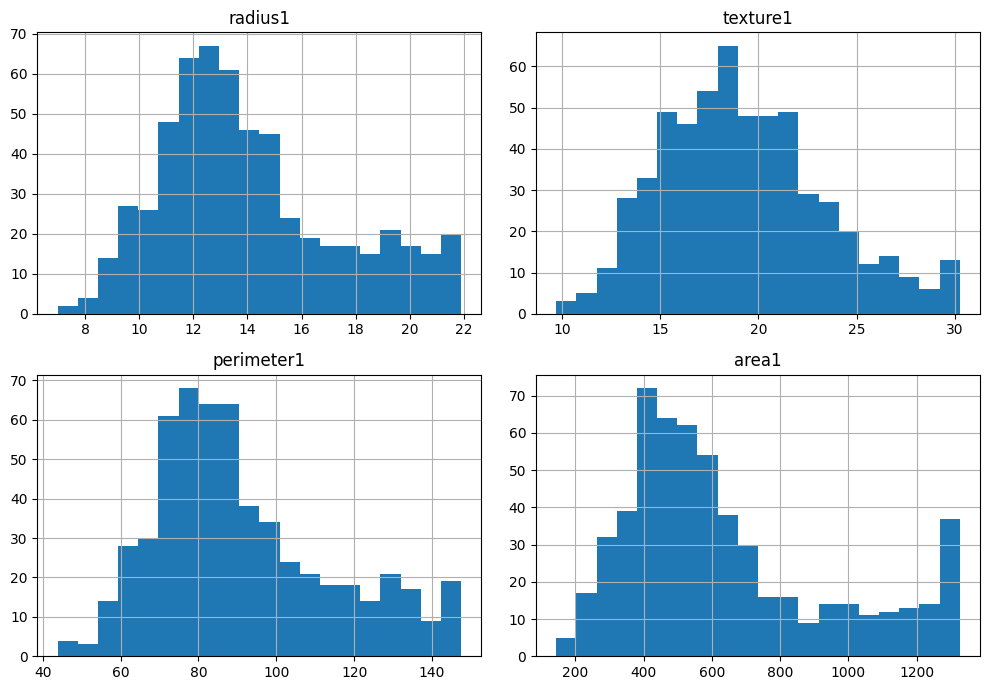

In [7]:
selected = feature_columns[:4]

clean_df[selected].hist(
    figsize=(10, 7),
    bins=20
)

plt.tight_layout()
plt.show()

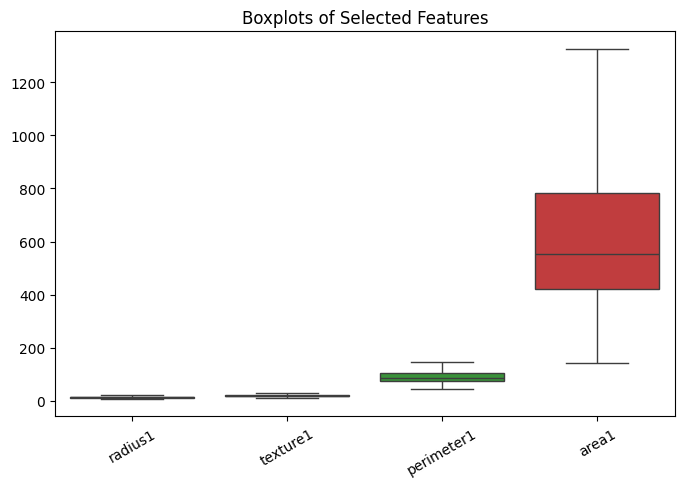

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df[selected])
plt.xticks(rotation=30)
plt.title("Boxplots of Selected Features")
plt.show()

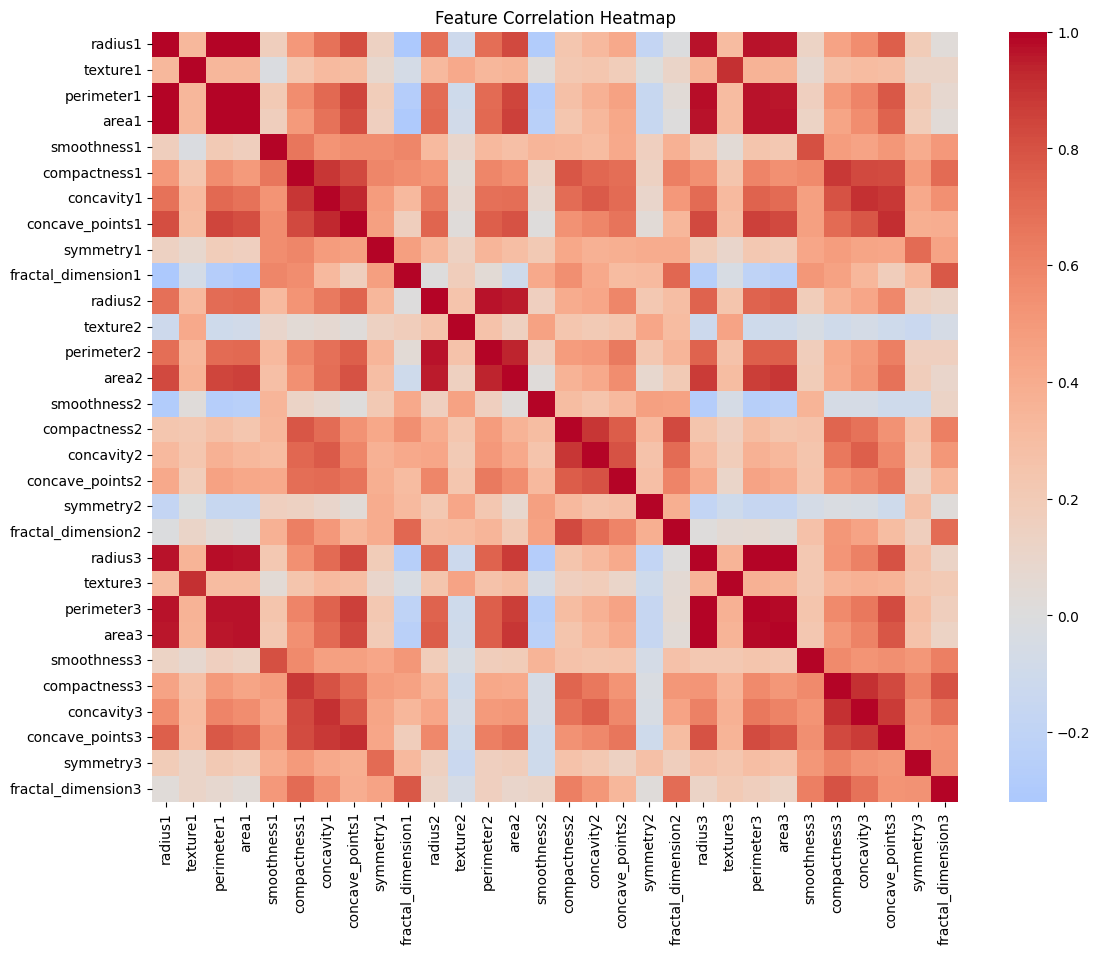

In [9]:
plt.figure(figsize=(13, 10))
sns.heatmap(
    clean_df[feature_columns].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Heatmap")
plt.show()

## Class Distribution

,Count,Percentage
Diagnosis,,
B,357,62.74
M,212,37.26


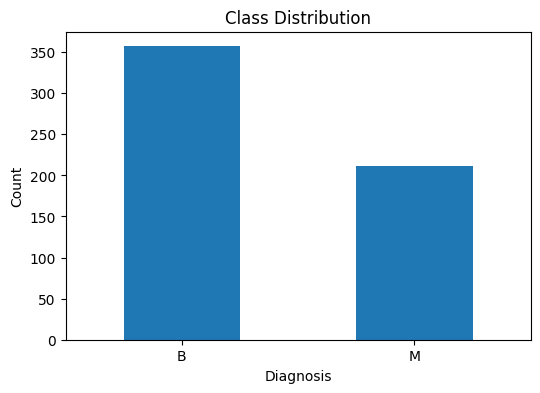

In [10]:
class_counts = clean_df[target_name].value_counts()
class_percent = clean_df[target_name].value_counts(normalize=True).mul(100).round(2)

display(pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent
}))

class_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

The dataset has more benign than malignant cases. Stratified splitting is used so both training and testing sets preserve the class proportions.

## Data Preprocessing

In [11]:
model_df = clean_df.copy()

model_df[target_name] = model_df[target_name].map({
    "B": 0,
    "M": 1
})

X = model_df[feature_columns]
y = model_df[target_name]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print(y_train.value_counts(normalize=True).round(3))

Training shape: (455, 30)
Testing shape: (114, 30)
Diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64


## Logistic Regression

In [12]:
model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model.fit(
    X_train_scaled,
    y_train
)

y_pred = model.predict(
    X_test_scaled
)

y_prob = model.predict_proba(
    X_test_scaled
)[:, 1]

## Evaluation

In [13]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

auc = roc_auc_score(
    y_test,
    y_prob
)

print("Accuracy:", round(accuracy, 4))
print("ROC AUC:", round(auc, 4))
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

Accuracy: 0.9649
ROC AUC: 0.9964

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Confusion Matrix

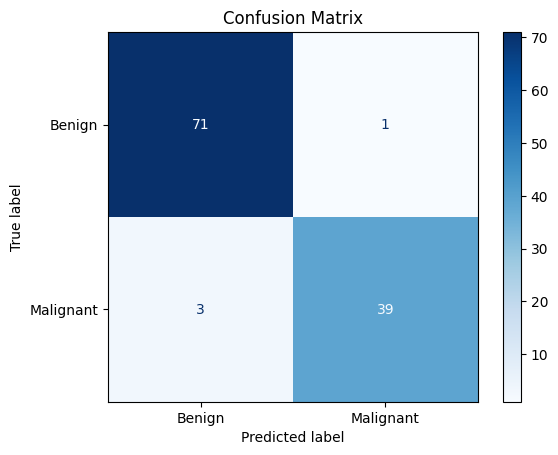

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

display_cm.plot(
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

## ROC Curve

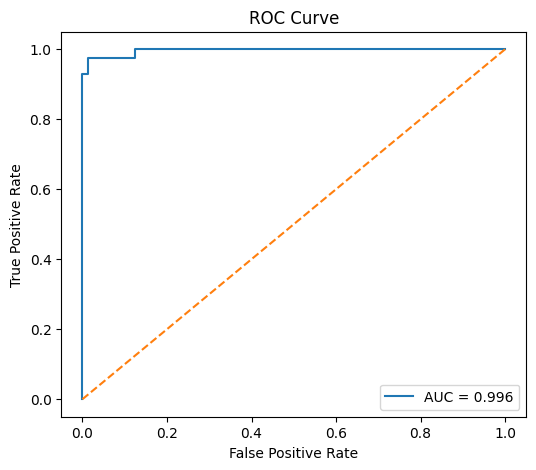

In [15]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## Result Interpretation

In [16]:
false_negatives = cm[1, 0]
malignant_total = cm[1].sum()
malignant_recall = cm[1, 1] / malignant_total

print("Malignant recall:", round(malignant_recall, 4))
print("False negatives:", false_negatives)
print("AUC:", round(auc, 4))

Malignant recall: 0.9286
False negatives: 3
AUC: 0.9964


In a medical diagnosis task, recall for the malignant class is especially important because a false negative means a malignant case is predicted as benign. Accuracy should therefore be considered together with recall, the confusion matrix and ROC-AUC.

## Regularization

In [17]:
regularization_results = []

for c_value in [0.01, 0.1, 1, 10, 100]:
    reg_model = LogisticRegression(
        C=c_value,
        max_iter=2000,
        random_state=42
    )
    reg_model.fit(
        X_train_scaled,
        y_train
    )
    score = reg_model.score(
        X_test_scaled,
        y_test
    )
    regularization_results.append([
        c_value,
        score
    ])

pd.DataFrame(
    regularization_results,
    columns=["C", "Test Accuracy"]
)

,C,Test Accuracy
0,0.01,0.947368
1,0.10,0.982456
2,1.00,0.964912
3,10.00,0.973684
4,100.00,0.938596


## Model Interpretation

In [18]:
coefficients = pd.Series(
    model.coef_[0],
    index=feature_columns
)

important_features = coefficients.abs().sort_values(
    ascending=False
).head(10).index

pd.DataFrame({
    "Feature": important_features,
    "Coefficient": coefficients[important_features].values
})

,Feature,Coefficient
0,texture3,1.468068
1,area2,1.160746
2,symmetry3,1.041055
3,compactness2,-1.024224
4,concave_points1,0.900704
5,radius2,0.874900
6,concavity3,0.845184
7,area3,0.803073
8,concavity1,0.765327
9,fractal_dimension2,-0.709758


## Conclusion
The Breast Cancer Wisconsin dataset was explored, cleaned, standardized and used to train a binary logistic regression model. Performance was evaluated using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC, followed by a basic regularization and coefficient analysis.